In [1]:
import numpy as np
import torch
import random
import os
import json
import argparse

from torch.nn import Parameter
from matplotlib import pyplot as plt
from mpl_toolkits.axes_grid1 import ImageGrid
from pathlib import Path
from scipy.interpolate import interp1d
from dolfin import *
from torch.optim import Adam
from gpytorch.optim import NGD

from alfi.models import TrainMode, MultiOutputGP, PartialLFM, generate_multioutput_gp
from alfi.impl.pdes import ReactionDiffusion
from alfi.utilities.data import dros_ground_truth
from alfi.utilities.fenics import interval_mesh
from alfi.datasets import DrosophilaSpatialTranscriptomics, HomogeneousReactionDiffusion
from alfi.trainers import PartialPreEstimator, PDETrainer
from alfi.plot import plot_spatiotemporal_data, Plotter1d
from alfi.utilities.torch import softplus, inv_softplus, q2, cia, smse
from alfi.configuration import VariationalConfiguration


/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/ufl/__init__.py:250: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
def load_model(experiment_dir, existing_model, gp_kwargs, inducing_points, lengthscale, zero_mean, lfm_args, lfm_cls, num_epochs=300):
    # NOTE change num_epochs to be matched alternatively
    filepath = str(num_epochs) +"epochs_trained_"   # Specify the file path to save the model
    experiment_name = existing_model
    gp_args = [1, inducing_points]
    gp_model = generate_multioutput_gp(
        *gp_args,
        initial_lengthscale=lengthscale,
        ard_dims=2,
        zero_mean=zero_mean,
        gp_kwargs=gp_kwargs)
    gp_args = [gp_model.mean_module, gp_model.covar_module] + [gp_args[1], gp_args[0]]
    lfm = lfm_cls.load(experiment_dir+"/"+ experiment_name + "/" + filepath,
                        gp_cls=MultiOutputGP,
                        gp_args=gp_args,
                        gp_kwargs=gp_kwargs,
                        lfm_args=lfm_args)
    # lfm = PartialLFM(1, gp_model, fenics_model, fenics_params, config)

    gp_model = lfm.gp_model

    return lfm, gp_model, num_epochs

def evaluate_model(lfm, trainer, plot=False, scaler=None, path="", inv_G=None):
    tx = trainer.tx
    disc = trainer.disc
    h = lfm(tx, step=disc)
    h_mean_unscaled = h.mean.detach()
    h_var_unscaled = h.variance.detach()
    y_target_unscaled = trainer.y_target[0]
    if scaler is not None:
        h_mean = torch.tensor(scaler.inverse_transform(h_mean_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        y_target = torch.tensor(scaler.inverse_transform(y_target_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        prot_q2 = q2(y_target, h_mean.squeeze()).item()
        prot_smse = smse(y_target, h_mean.squeeze()).mean().item()
    else:
        prot_q2 = q2(y_target_unscaled.squeeze(), h_mean_unscaled.squeeze()).item()
        prot_smse = smse(y_target_unscaled.squeeze(), h_mean_unscaled.squeeze()).mean().item()

    prot_cia = cia(y_target_unscaled, h_mean_unscaled.squeeze(), h_var_unscaled.squeeze()).item()

    if plot:
        if not scaler:
            h_mean = h_mean_unscaled
            y_target = y_target_unscaled
        tx = trainer.tx
        num_t = 8
        num_x = h_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(h_mean.min(), y_target.min())
        y_max = max(h_mean.max(), y_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        prot_axes = plot_spatiotemporal_data(
            [h_mean.detach().view(num_t, num_x).t(),
             y_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )

    f = lfm.gp_model(trainer.tx.t())
    lf_target_unscaled = trainer.lf_target.squeeze()
    num_t = trainer.num_t
    num_x = trainer.num_x
    f_mean_unscaled = f.mean.reshape(num_t, num_x)[::disc].reshape(-1)
    f_var_unscaled = f.variance.reshape(num_t, num_x)[::disc].reshape(-1)
    f_mean_unscaled = lfm.G(f_mean_unscaled)
    if scaler is not None:
        f_mean = torch.tensor(scaler.inverse_transform(f_mean_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        lf_target = torch.tensor(scaler.inverse_transform(lf_target_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        mrna_q2 = q2(lf_target, f_mean.squeeze()).item()
        mrna_smse = smse(lf_target, f_mean.squeeze()).mean().item()
        if inv_G:
            lf_target_inv = inv_G(lf_target_unscaled)
            f_mean_inv = inv_G(lf_target_unscaled)
            mrna_cia = cia(lf_target_inv, f_mean_inv.squeeze(), f_var_unscaled.squeeze()).item()
    else:
        mrna_q2 = q2(lf_target_unscaled.squeeze(), f_mean_unscaled.squeeze()).item()
        mrna_smse = smse(lf_target_unscaled.squeeze(), f_mean_unscaled.squeeze()).mean().item()
    mrna_cia = cia(lf_target_unscaled, f_mean_unscaled.squeeze(), f_var_unscaled.squeeze()).item()


    if plot:
        if not scaler:
            f_mean = f_mean_unscaled
            lf_target = lf_target_unscaled
        tx = trainer.tx
        num_t = 8
        num_x = f_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(f_mean.min(), lf_target.min())
        y_max = max(f_mean.max(), lf_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        mrna_axes = plot_spatiotemporal_data(
            [f_mean.detach().view(num_t, num_x).t(),
             lf_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )
    if plot:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse, prot_axes, mrna_axes
    else:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse

In [2]:
experiment_names = {"0kr":[],"1kr":[],"2kr":[]}
experiment_dir = "experiment_results"
for subdir in os.listdir(experiment_dir):
    included = False
    if subdir.startswith("0kr"):
        prefix = "0kr"
        experiment_names[prefix].append(str(subdir))
    elif subdir.startswith("1kr"):
        prefix = "1kr"
        experiment_names[prefix].append(str(subdir))
    elif subdir.startswith("2kr"):
        prefix = "2kr"
        experiment_names[prefix].append(str(subdir))

print(experiment_names)

{'0kr': ['0kr_42_1755779586.375811final-no-zero-mean-sample-10-lr-0.005', '0kr_45_1755785922.449753final-no-zero-mean-sample-10-lr-0.005', '0kr_43_1755779586.375809final', '0kr_0_1755281656.617344no-natural-sample-10-no-zero-mean', '0kr_44_1755785922.4498932final-no-zero-mean-sample-10-lr-0.005'], '1kr': ['1kr_43_1755729475.943425final-no-zero-mean-sample-10-trans-1-lr-0.005-minmax', '1kr_45_1755752051.1141498final-no-zero-mean-sample-10-trans-1-lr-0.005-minmax', '1kr_0_1755695960.990571no-zero-mean-sample--10-transformation-lr-0.01-minmax', '1kr_44_1755740446.126104final-no-zero-mean-sample-10-trans-1-lr-0.005-minmax', '1kr_42_1755718121.0981271final-no-zero-mean-sample-10-trans-1-lr-0.005-minmax'], '2kr': ['2kr_44_1755740446.126102final-no-zero-mean-sample-10-trans-5-lr-0.005-minmax', '2kr_0_1755697280.241066no-zero-mean-sample--10-trans-5-lr-0.01-minmax', '2kr_43_1755729475.9435232final-no-zero-mean-sample-10-trans-5-lr-0.005-minmax', '2kr_45_1755752051.114048final-no-zero-mean-samp

Gene name: kr
tx torch.Size([2, 512])
x dp is set to tensor(1., dtype=torch.float64)
No!


/Users/user/Documents/GitHub/alfi/pde_experiment.py:355: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)
/opt/miniconda3/envs/local_alfi/lib/python3.9/site-packages/torchcubicspline/interpolate.py:277: UserWarning: torch.searchsorted(): boundary tensor is non-contiguous, this will lower the performance due to extra data copy when converting non-contiguous tensor to contiguous, please use contiguous boundary tensor if possible. This message will only appear once per program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/BucketizationUtils.h:40.)
  index = torch.bucketize(t.detach(), self._t) - 1


y_min: -28.628404662773523, y_max: 211.15
y_min: -17.45616360189054, y_max: 214.24524326190183
Gene name: kr
tx torch.Size([2, 512])
x dp is set to tensor(1., dtype=torch.float64)
No!


/Users/user/Documents/GitHub/alfi/pde_experiment.py:355: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)


y_min: -32.23112339314878, y_max: 211.15
y_min: -16.68445475429512, y_max: 213.7791484713129
hello
Gene name: kr
tx torch.Size([2, 512])
x dp is set to tensor(1., dtype=torch.float64)
Yes!


...

y_min: 0.0, y_max: 220.94304395905942
y_min: 0.0, y_max: 225.87027321550093
{'prot_q2': 0.8657850502745453, 'prot_cia': 0.19921875, 'prot_smse': 0.1339528111517722, 'mrna_q2': 0.9131581716480229, 'mrna_cia': 1.0, 'mrna_smse': 0.08667221540597707}
Gene name: kr
tx torch.Size([2, 512])
x dp is set to tensor(1., dtype=torch.float64)
No!


/Users/user/Documents/GitHub/alfi/pde_experiment.py:355: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)


y_min: -43.45247541352025, y_max: 211.15
y_min: -15.40327398527692, y_max: 238.21041487416798
Gene name: kr
tx torch.Size([2, 512])
x dp is set to tensor(1., dtype=torch.float64)
No!


/Users/user/Documents/GitHub/alfi/pde_experiment.py:355: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)


y_min: -49.03642125959771, y_max: 217.40027860538882
y_min: -12.733080693448311, y_max: 221.0017566669915


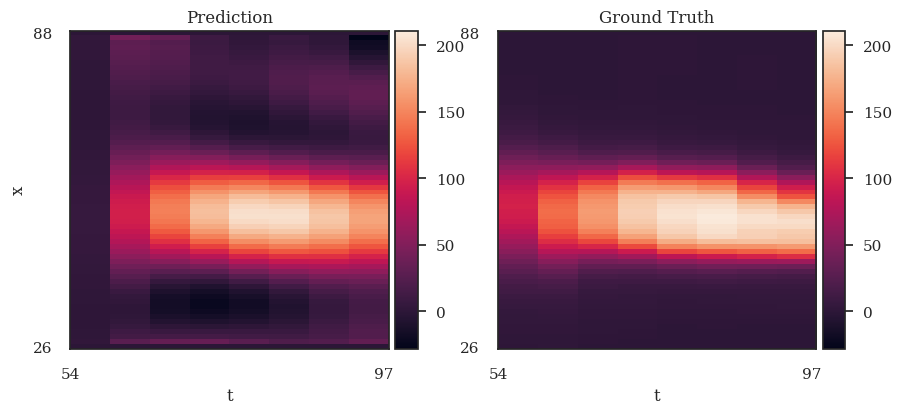

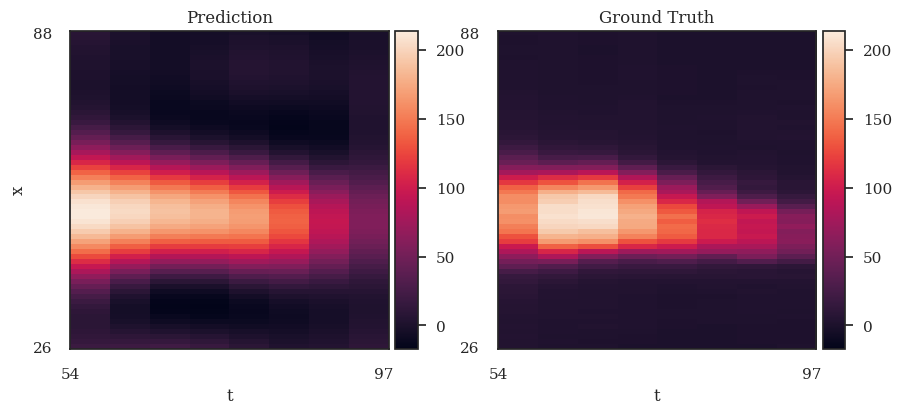

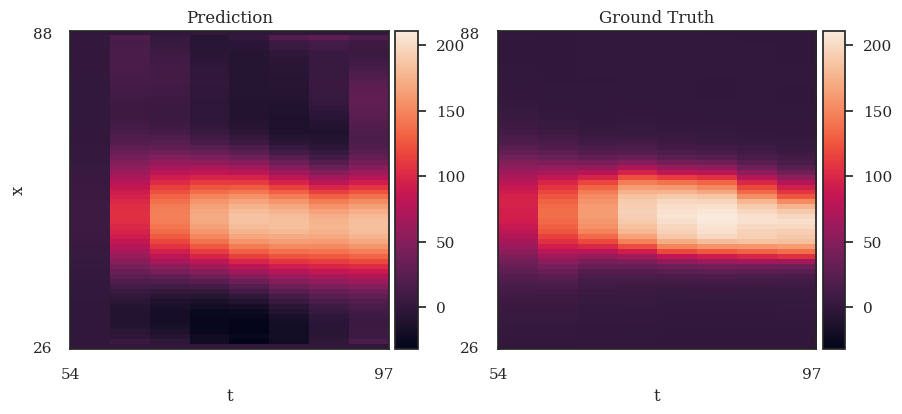

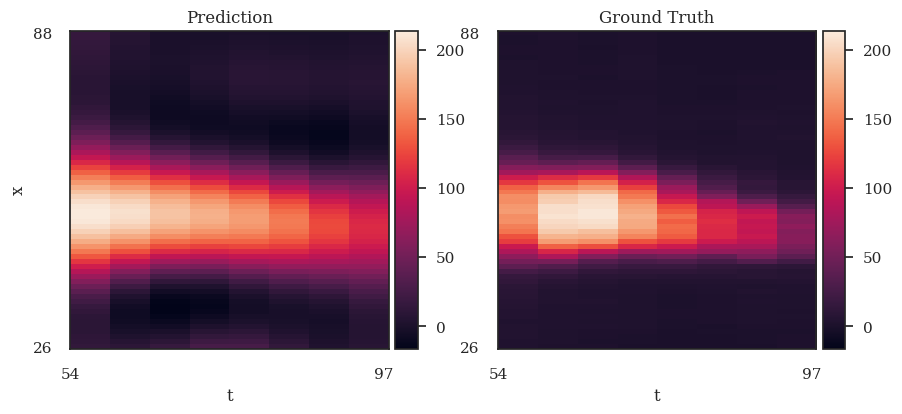

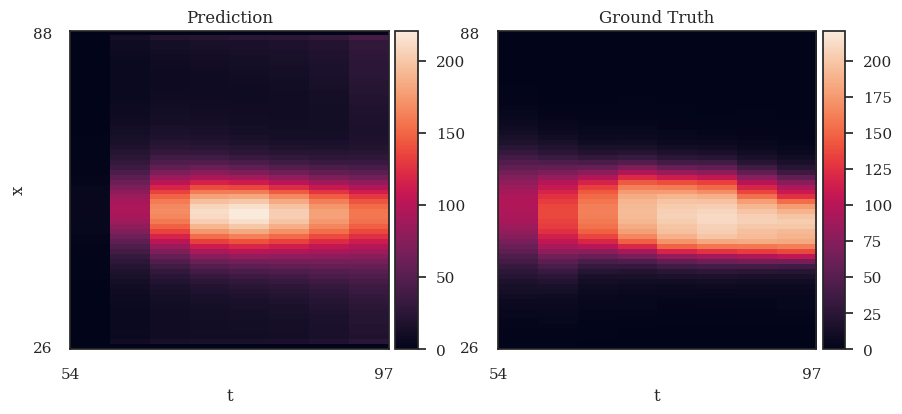

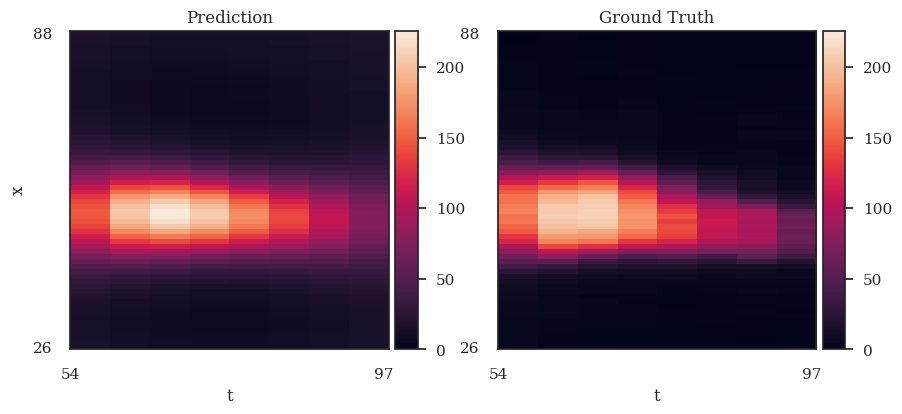

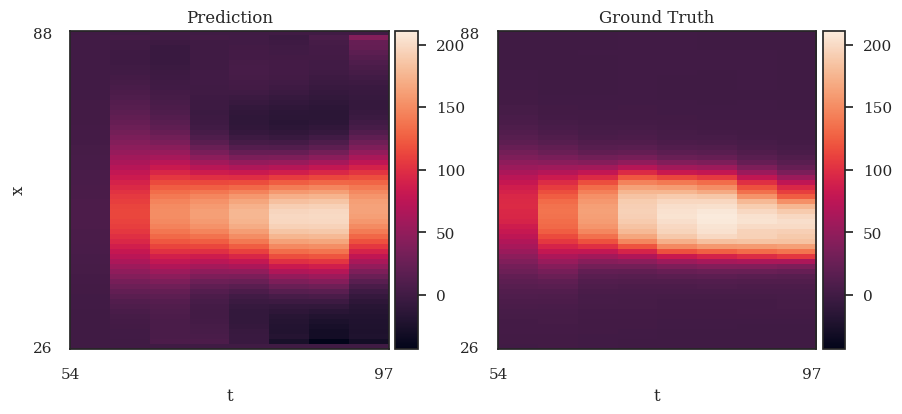

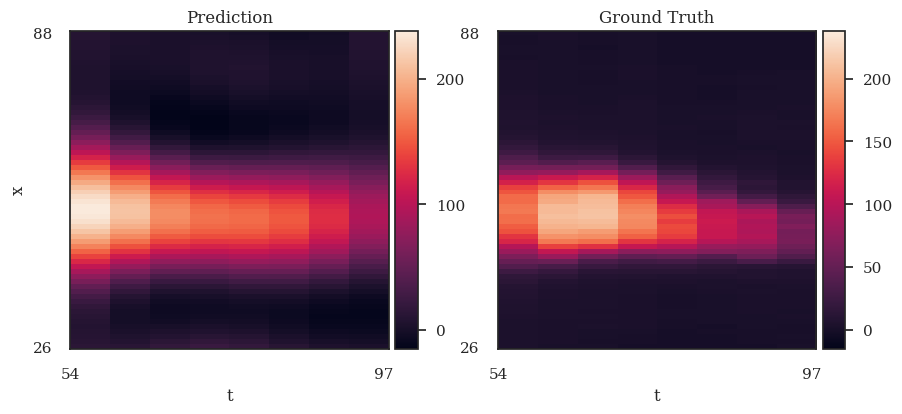

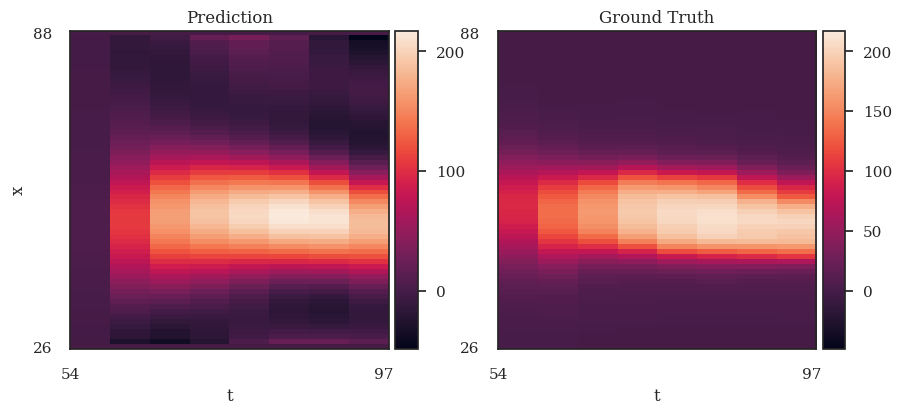

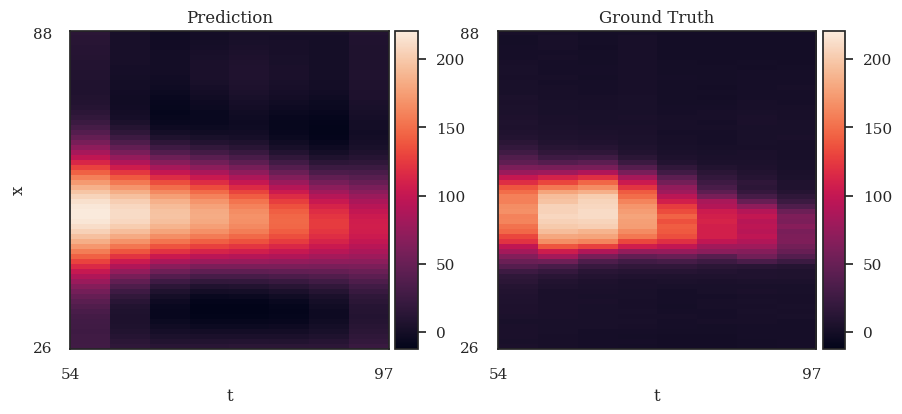

In [4]:
from pde_experiment import evaluate_model, main
prefix = "1kr"
corrected_results = {"1kr":{}, "2kr":{}, "0kr":{}}
keys = ['prot_q2', 'mrna_q2', 'prot_cia', 'mrna_cia']
gene = "kr"
for key in keys:
    corrected_results[key] = []
for experiment_name in experiment_names[prefix]:
    SEED = int(experiment_name.split("_")[1])
    print_res = False 
    if "0.01" in experiment_name:
        transformation = "softplus"
        print("hello")
        print_res = True
    else:
        transformation = "softplus_1"
    if prefix == "1kr":
        dataset = DrosophilaSpatialTranscriptomics(
            gene=gene, data_dir='./data', scale="minmax",disc=20)
        lfm, gp, trainer = main("kr", SEED, drosophila=True, use_lhs=True, train_ratio=0.3, skip=False, learn_inducing_locations=False, gp_use_tril=True, params_grad=False, experiment_dir="experiment_results", note="", max_epoch=500, debug=False, transformation=transformation,lr=0.005, existing_model=experiment_name)
    if not print_res:
        inv_G = None
        print("No!")
    else:
        inv_G = lambda u: inv_softplus(u, beta=1)
        print("Yes!")
    lfm.eval()
    prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse, prot_axes, mrna_axes = evaluate_model(lfm, trainer, plot=True, scaler=dataset.scaler, path=f"{experiment_dir}/{experiment_name}", inv_G=inv_G)
    result_dict = {
        'prot_q2': prot_q2,
        'prot_cia': prot_cia,
        'prot_smse': prot_smse,
        'mrna_q2': mrna_q2,
        'mrna_cia': mrna_cia,
        'mrna_smse': mrna_smse
    }
    if print_res:
        print(result_dict)
    for key in keys:
        corrected_results[key].append(result_dict[key])

In [5]:
print(corrected_results["mrna_cia"])

[0.923828125, 0.888671875, 1.0, 0.84765625, 0.880859375]


In [10]:
experiment_dir = "experiment_results"
gene = "kr"
prefix = "2kr"
if prefix == "0kr":
    transformation = ""
elif prefix == "1kr":
    transformation = "softplus_1"
elif prefix == "2kr":
    transformation = "softplus_5"
experiment_name = experiment_names[prefix][1]
SEED = int(experiment_name.split("_")[1])
dataset = DrosophilaSpatialTranscriptomics(
            gene=gene, data_dir='./data', scale="minmax",disc=20)
minmax_scaler = dataset.scaler

dataset = DrosophilaSpatialTranscriptomics(
    gene=gene, data_dir='./data', scale=True, disc=20) # data folder
standard_scaler = dataset.scaler 
from pde_experiment import main

lfm, gp, trainer = main(gene, SEED, drosophila=True, use_lhs=True, train_ratio=0.3, skip=False, learn_inducing_locations=False, gp_use_tril=True, params_grad=False, experiment_dir="experiment_results", note="", max_epoch=500, debug=False, transformation=transformation,lr=0.005, existing_model=experiment_name)


Gene name: kr
tx torch.Size([2, 512])
x dp is set to tensor(1., dtype=torch.float64)


/Users/user/Documents/GitHub/alfi/pde_experiment.py:355: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  latent = torch.tensor(orig_data[trainer.t_sorted, 2]).unsqueeze(0)


In [ ]:
def evaluate_model(lfm, trainer, plot=False, scaler=None, path="", inv_G=None, slice_t=None, slice_x=None):
    disc = trainer.disc
    h = lfm(tx, step=disc)
    h_mean_unscaled = h.mean.detach()
    h_var_unscaled = h.variance.detach()
    y_target_unscaled = trainer.y_target[0]
    num_t = 8
    num_x = h_mean_unscaled.shape[0] // num_t
    if scaler is not None:
        h_mean = torch.tensor(scaler.inverse_transform(h_mean_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        y_target = torch.tensor(scaler.inverse_transform(y_target_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        prot_q2 = q2(y_target, h_mean.squeeze()).item()
        prot_smse = smse(y_target, h_mean.squeeze()).mean().item()
    else:
        prot_q2 = q2(y_target_unscaled.squeeze(), h_mean_unscaled.squeeze()).item()
        prot_smse = smse(y_target_unscaled.squeeze(), h_mean_unscaled.squeeze()).mean().item()

    prot_cia = cia(y_target_unscaled, h_mean_unscaled.squeeze(), h_var_unscaled.squeeze()).item()

    if plot:
        if not scaler:
            h_mean = h_mean_unscaled
            y_target = y_target_unscaled
        tx = trainer.tx
        num_t = 8
        num_x = h_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(h_mean.min(), y_target.min())
        y_max = max(h_mean.max(), y_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        prot_axes = plot_spatiotemporal_data(
            [h_mean.detach().view(num_t, num_x).t(),
             y_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )

    f = lfm.gp_model(trainer.tx.t())
    lf_target_unscaled = trainer.lf_target.squeeze()
    num_t = trainer.num_t
    num_x = trainer.num_x
    f_mean_unscaled = f.mean.reshape(num_t, num_x)[::disc].reshape(-1)
    f_var_unscaled = f.variance.reshape(num_t, num_x)[::disc].reshape(-1)
    f_mean_unscaled = lfm.G(f_mean_unscaled)
    if scaler is not None:
        f_mean = torch.tensor(scaler.inverse_transform(f_mean_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        lf_target = torch.tensor(scaler.inverse_transform(lf_target_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        mrna_q2 = q2(lf_target, f_mean.squeeze()).item()
        mrna_smse = smse(lf_target, f_mean.squeeze()).mean().item()
        if inv_G:
            lf_target_inv = inv_G(lf_target_unscaled)
            f_mean_inv = inv_G(lf_target_unscaled)
            mrna_cia = cia(lf_target_inv, f_mean_inv.squeeze(), f_var_unscaled.squeeze()).item()
    else:
        mrna_q2 = q2(lf_target_unscaled.squeeze(), f_mean_unscaled.squeeze()).item()
        mrna_smse = smse(lf_target_unscaled.squeeze(), f_mean_unscaled.squeeze()).mean().item()
    mrna_cia = cia(lf_target_unscaled, f_mean_unscaled.squeeze(), f_var_unscaled.squeeze()).item()

    if plot:
        if not scaler:
            f_mean = f_mean_unscaled
            lf_target = lf_target_unscaled
        tx = trainer.tx
        num_t = 8
        num_x = f_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(f_mean.min(), lf_target.min())
        y_max = max(f_mean.max(), lf_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        mrna_axes = plot_spatiotemporal_data(
            [f_mean.detach().view(num_t, num_x).t(),
             lf_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )
    if plot:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse, prot_axes, mrna_axes
    else:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse


In [11]:
disc = trainer.disc
# tx = trainer.tx
# h = lfm(tx, step=disc)
# h_mean_unscaled = h.mean.detach()
# h_var_unscaled = h.variance.detach()
# y_target_unscaled = trainer.y_target[0]
# print(h_mean_unscaled.shape)

In [12]:
tx = trainer.tx
ts = tx[0, :].unique().sort()[0].numpy()
xs = tx[1, :].unique().sort()[0].numpy()
f = gp(tx.t())
print(ts.shape)
print(xs.shape)

# slice_at_x = tx[:,custom_x::64]
lfm.config.num_samples = 50
h = lfm(tx, step=1) # disc = 1 gives very continous function

(141,)
(64,)


In [13]:
# import pandas as pd

def transformation_back(x, prefix="0kr", h=True, scale=True):
    if prefix =="1kr" and not h:
        x = softplus(x, beta=1)
        pass
    elif prefix == "2kr" and not h:
        # x = softplus(x, beta=5)
    else:
        print("yes")
    if not scale:        
        return x
    else:
        if prefix == "0kr":
            return standard_scaler.inverse_transform(x)
        else:
            return minmax_scaler.inverse_transform(x)

def plot_hx(h, custom_x, prefix, scale=True):
    # custom_x = 30 # ranged from 0 to 63
    n = 1
    if prefix == "0kr":
        scaler = standard_scaler
    else:
        scaler = minmax_scaler
    h_mean_slice_x = h.mean.detach()[custom_x::64]
    h_var_slice_x = h.mean.detach()[custom_x::64]
    h_ub_unscaled = h_mean_slice_x + n * h_var_slice_x
    h_lb_unscaled = h_mean_slice_x - n * h_var_slice_x
    h_mean = transformation_back(h_mean_slice_x, prefix=prefix, h=True, scale=scale).reshape(-1)
    h_ub = transformation_back(h_ub_unscaled, prefix=prefix, h=True,scale=scale).reshape(-1)
    h_lb = transformation_back(h_lb_unscaled, prefix=prefix, h=True,scale=scale).reshape(-1)
    if scale and prefix != "0kr":
        h_mean -= min(h_lb)
        h_ub -= min(h_lb)
    if scale:
        y_target = scaler.inverse_transform(trainer.y_target[0].reshape(-1,1))[custom_x::64]
        if prefix != "0kr":
            y_target -= min(h_lb) 
            h_lb -= min(h_lb)
    y_target = trainer.y_target[0].reshape(-1,1)[custom_x::64]
    
    ts_gap = ts[::disc]
    
    color_map = ["steelblue", "lightblue", "tomato"]
    
    plt.plot(ts, h_mean, color=color_map[0], label="mean")
    plt.plot(ts, h_ub, color=color_map[1], label=f"mean + {n}sd")
    plt.plot(ts, h_lb, color=color_map[1], label=f"mean - {n}sd")
    plt.plot(ts_gap, y_target, "o--", color=color_map[2], label="target")
    plt.fill_between(ts, h_lb, h_ub, color="lightblue", alpha=0.5, label="68% confidence interval")
    plt.title(f"Predictive distribution of protein at x={xs[custom_x]}")
    plt.xlabel("time")
    plt.legend()
    image_title = f"{prefix}_h_x{custom_x}"
    plt.savefig(f"{image_title}.pdf")

yes
yes
yes


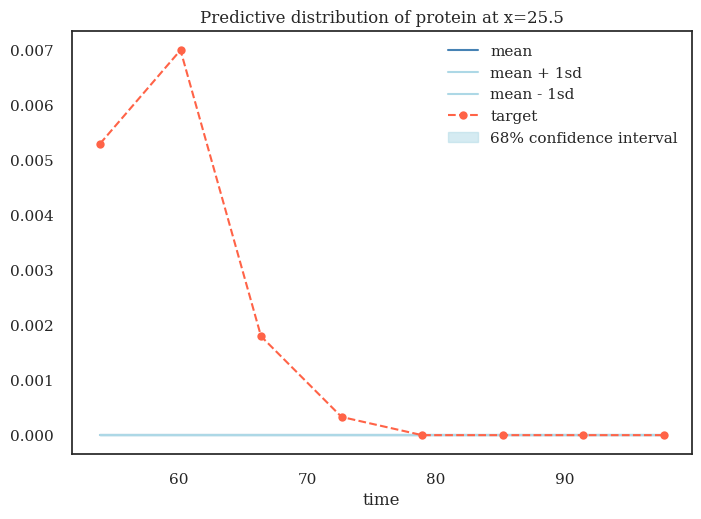

yes
yes
yes


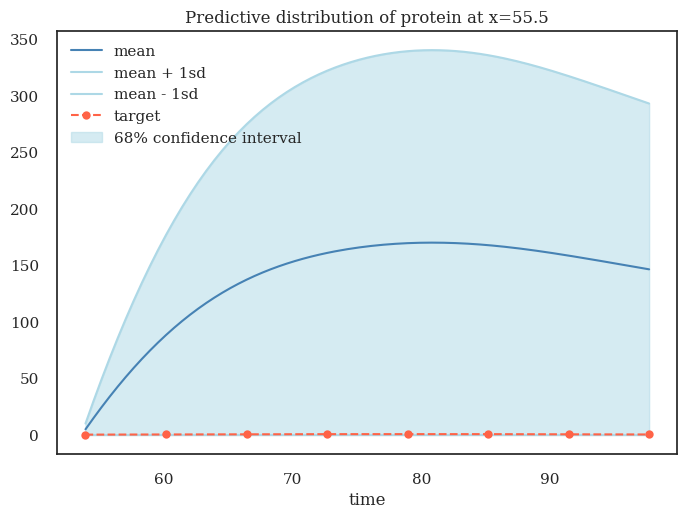

yes
yes
yes


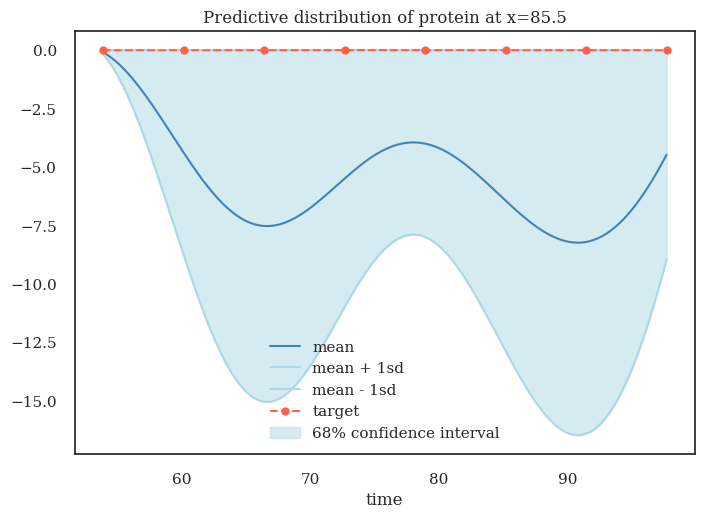

In [14]:
for x in [0, 30, 60]:
    plot_hx(h, custom_x=x, prefix=prefix, scale=True)
    plt.show()

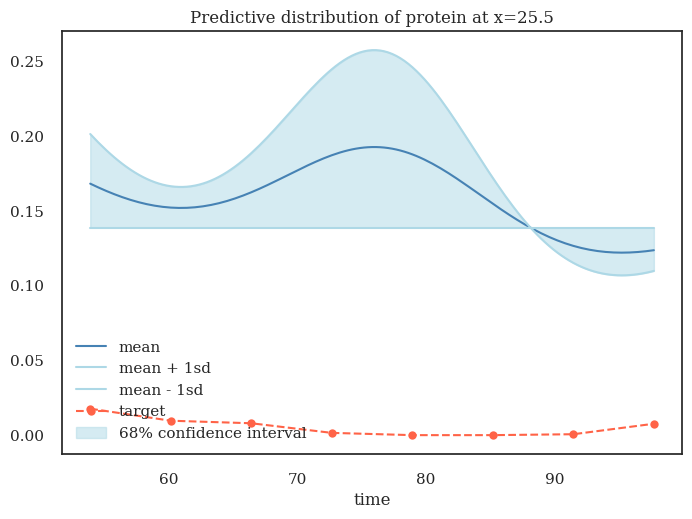

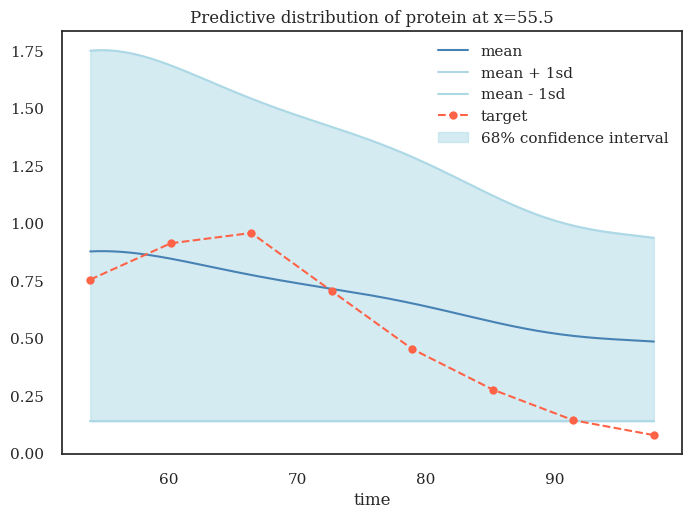

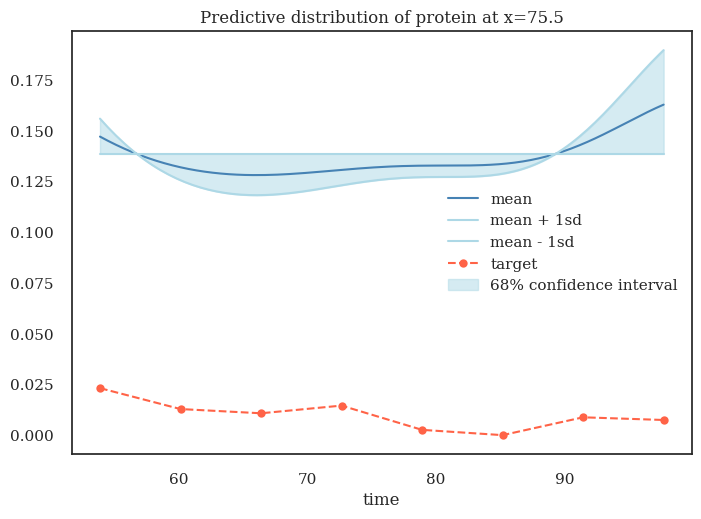

In [23]:
def plot_fx(f, custom_x, prefix, scale=True):
    # custom_x = 30 # ranged from 0 to 63
    n = 1
    if prefix == "0kr":
        scaler = standard_scaler
    else:
        scaler = minmax_scaler
    
    f_mean_slice_x = f.mean.detach()[custom_x::64]
    f_var_slice_x = f.mean.detach()[custom_x::64]
    # f_var_slice_x = torch.clamp(f_var_slice_x, min=0.0)
    f_ub_unscaled = f_mean_slice_x + n * f_var_slice_x
    f_lb_unscaled = f_mean_slice_x - n * f_var_slice_x
    f_mean = transformation_back(f_mean_slice_x, prefix=prefix, h=False, scale=scale).reshape(-1)
    f_ub = transformation_back(f_ub_unscaled, prefix=prefix, h=False,scale=scale).reshape(-1)
    f_lb = transformation_back(f_lb_unscaled, prefix=prefix, h=False,scale=scale).reshape(-1)
    if scale and prefix != "0kr":
        f_mean -= min(f_lb)
        f_ub -= min(f_lb)
    lf_target = trainer.lf_target.squeeze()
    if scale:
        lf_target = scaler.inverse_transform(lf_target.reshape(-1,1))
        if prefix != "0kr":
            # lf_target -= min(f_lb)
            f_lb -= min(f_lb)
    lf_target = lf_target [custom_x::64]
    ts_gap = ts[::disc]
    
    color_map = ["steelblue", "lightblue", "tomato"]
    
    
    plt.plot(ts, f_mean, color=color_map[0], label="mean")
    plt.plot(ts, f_ub, color=color_map[1], label=f"mean + {n}sd")
    plt.plot(ts, f_lb, color=color_map[1], label=f"mean - {n}sd")
    plt.plot(ts_gap, lf_target, "o--", color=color_map[2], label="target")
    plt.fill_between(ts, f_lb, f_ub, color="lightblue", alpha=0.5, label="68% confidence interval")
    plt.title(f"Predictive distribution of protein at x={xs[custom_x]}")
    plt.xlabel("time")
    plt.legend()
    image_title = f"{prefix}_f_x{custom_x}"
    plt.savefig(f"{image_title}.pdf")
for x in [0, 30, 50]:
    plot_fx(f, custom_x=x, prefix=prefix, scale=False)
    plt.show()

In [24]:
corrected_results 

NameError: name 'corrected_results' is not defined

In [ ]:
print(prefix)

In [ ]:
plt.plot(y_target)

In [ ]:
plt.plot(h_lb_unscaled)

In [ ]:
def evaluate_model(lfm, trainer, plot=False, scaler=None, path="", inv_G=None, slice_t=None, slice_x=None):

    disc = trainer.disc
    h = lfm(tx, step=disc)
    h_mean_unscaled = h.mean.detach()
    h_var_unscaled = h.variance.detach()
    y_target_unscaled = trainer.y_target[0]

    if scaler is not None:
        h_mean = torch.tensor(scaler.inverse_transform(h_mean_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        y_target = torch.tensor(scaler.inverse_transform(y_target_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        prot_q2 = q2(y_target, h_mean.squeeze()).item()
        prot_smse = smse(y_target, h_mean.squeeze()).mean().item()
    else:
        prot_q2 = q2(y_target_unscaled.squeeze(), h_mean_unscaled.squeeze()).item()
        prot_smse = smse(y_target_unscaled.squeeze(), h_mean_unscaled.squeeze()).mean().item()

    prot_cia = cia(y_target_unscaled, h_mean_unscaled.squeeze(), h_var_unscaled.squeeze()).item()

    if plot:
        if not scaler:
            h_mean = h_mean_unscaled
            y_target = y_target_unscaled
        tx = trainer.tx
        num_t = 8
        num_x = h_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(h_mean.min(), y_target.min())
        y_max = max(h_mean.max(), y_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        prot_axes = plot_spatiotemporal_data(
            [h_mean.detach().view(num_t, num_x).t(),
             y_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )

    f = lfm.gp_model(trainer.tx.t())
    lf_target_unscaled = trainer.lf_target.squeeze()
    num_t = trainer.num_t
    num_x = trainer.num_x
    f_mean_unscaled = f.mean.reshape(num_t, num_x)[::disc].reshape(-1)
    f_var_unscaled = f.variance.reshape(num_t, num_x)[::disc].reshape(-1)
    f_mean_unscaled = lfm.G(f_mean_unscaled)
    if scaler is not None:
        f_mean = torch.tensor(scaler.inverse_transform(f_mean_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        lf_target = torch.tensor(scaler.inverse_transform(lf_target_unscaled.detach().numpy().reshape(-1, 1))).view(-1)
        mrna_q2 = q2(lf_target, f_mean.squeeze()).item()
        mrna_smse = smse(lf_target, f_mean.squeeze()).mean().item()
        if inv_G:
            lf_target_inv = inv_G(lf_target_unscaled)
            f_mean_inv = inv_G(lf_target_unscaled)
            mrna_cia = cia(lf_target_inv, f_mean_inv.squeeze(), f_var_unscaled.squeeze()).item()
    else:
        mrna_q2 = q2(lf_target_unscaled.squeeze(), f_mean_unscaled.squeeze()).item()
        mrna_smse = smse(lf_target_unscaled.squeeze(), f_mean_unscaled.squeeze()).mean().item()
    mrna_cia = cia(lf_target_unscaled, f_mean_unscaled.squeeze(), f_var_unscaled.squeeze()).item()

    if plot:
        if not scaler:
            f_mean = f_mean_unscaled
            lf_target = lf_target_unscaled
        tx = trainer.tx
        num_t = 8
        num_x = f_mean.shape[0] // num_t

        ts = tx[0, :].unique().sort()[0].numpy()
        xs = tx[1, :].unique().sort()[0].numpy()
        extent = [ts[0], ts[-1], xs[0], xs[-1]]
        y_min = min(f_mean.min(), lf_target.min())
        y_max = max(f_mean.max(), lf_target.max())
        print(f"y_min: {y_min}, y_max: {y_max}")
        mrna_axes = plot_spatiotemporal_data(
            [f_mean.detach().view(num_t, num_x).t(),
             lf_target.detach().view(num_t, num_x).t()
             ],
            extent,
            titles=['Prediction', "Ground Truth"],
            clim=[(y_min, y_max),(y_min, y_max)],
        )
    if plot:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse, prot_axes, mrna_axes
    else:
        return prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse


In [ ]:
dict(lfm.gp_model.named_variational_parameters()).keys();
dict(lfm.named_parameters()).keys()

In [ ]:
gene = "kni"
num_epochs = 300
use_lhs = True
train_ratio=0.3
skip=True
learn_inducing_locations=False
gp_use_tril=True
params_grad=False
experiment_dir="experiment_results"

dataset = DrosophilaSpatialTranscriptomics(
    gene=gene, data_dir='./data', scale=True, disc=20) # data folder
params = dict(lengthscale=10,
        **dros_ground_truth(gene),
        parameter_grad=False,
        natural=False,
        clamp=True)

disc = dataset.disc

data = next(iter(dataset))
tx, y_target = data
lengthscale = params['lengthscale']
zero_mean = params['zero_mean'] if 'zero_mean' in params else False

#### Generate FENiCS 1D mesh from the data
# Alternatively, if our spatial data is not uniformly spaced, we can define a custom mesh as follows.
# We calculate a mesh that contains all possible spatial locations in the dataset

spatial = np.unique(tx[1, :])
mesh = interval_mesh(spatial)


if tx.shape[1] > 1000:
    num_inducing = int(tx.shape[1] * 3/6)
else:
    num_inducing = int(tx.shape[1] * 5/6)
# whether inducing points should be sampled using LHS or random choice
if use_lhs:
    print('tx', tx.shape)
    from smt.sampling_methods import LHS
    ts = tx[0, :].unique().sort()[0].numpy()
    xs = tx[1, :].unique().sort()[0].numpy()
    xlimits = np.array([[ts[0], ts[-1]],[xs[0], xs[-1]]])
    sampling = LHS(xlimits=xlimits, random_state=np.random.RandomState(SEED))
    inducing_points = torch.tensor(sampling(num_inducing)).unsqueeze(0)
else:
    inducing_points = torch.stack([
        tx[0, torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:num_inducing]],
        tx[1, torch.randperm(tx.shape[1], generator=torch.Generator().manual_seed(SEED))[:num_inducing]]
    ], dim=1).unsqueeze(0)
gp_kwargs = dict(learn_inducing_locations=learn_inducing_locations,
                natural=params['natural'],
                use_tril=gp_use_tril)


ts = tx[0, :].unique().sort()[0].numpy()
t_range = (ts[0], ts[-1])
# :HP: number of time steps to discretise the PDE of the dataset
time_steps = dataset.num_discretised
fenics_model = ReactionDiffusion(t_range, time_steps, mesh)

# :HP: configuration for the variational inference, initial conditions, number of samples
config = VariationalConfiguration(
    initial_conditions=False,
    num_samples=5
)

# Set up the LFM
# include DE parameters
parameter_grad = params['parameter_grad'] if 'parameter_grad' in params else True
sensitivity = Parameter(
    inv_softplus(torch.tensor(params['sensitivity'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=False)
decay = Parameter(
    inv_softplus(torch.tensor(params['decay'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=parameter_grad)
diffusion = Parameter(
    inv_softplus(torch.tensor(params['diffusion'])) * torch.ones((1, 1), dtype=torch.float64),
    requires_grad=parameter_grad)

fenics_params = [sensitivity, decay, diffusion]
num_training = int(train_ratio * tx.shape[1])


In [ ]:
gp_args = [1, inducing_points]
gp_kwargs = dict(learn_inducing_locations=learn_inducing_locations,
                natural=params['natural'],
                use_tril=gp_use_tril)
gp_model = generate_multioutput_gp(
    *gp_args,
    initial_lengthscale=lengthscale,
    ard_dims=2,
    zero_mean=zero_mean,
    gp_kwargs=gp_kwargs)
gp_args = [gp_model.mean_module, gp_model.covar_module] + [gp_args[1], gp_args[0]]
filepath = str(num_epochs) +"epochs_trained_"   # Specify the file path to save the model
orig_data = dataset.orig_data.squeeze().t()
lfm = PartialLFM.load(experiment_dir+"/"+ experiment_name + "/" + filepath,
                    gp_cls=MultiOutputGP,
                    gp_args=gp_args,
                    gp_kwargs=gp_kwargs,
                    lfm_args=[1, fenics_model, fenics_params, config])
# lfm = PartialLFM(1, gp_model, fenics_model, fenics_params, config)

gp_model = lfm.gp_model
optimizer = [torch.optim.Adam(lfm.parameters(), lr=0.07)]
trainer = PDETrainer(lfm, optimizer, dataset, track_parameters=list(lfm.fenics_named_parameters.keys()), lf_target=orig_data)
lfm.eval()
prot_q2, prot_cia, prot_smse, mrna_q2, mrna_cia, mrna_smse = evaluate_model(lfm, trainer, scaler=dataset.scaler)
result_dict = {
    'prot_q2': prot_q2,
    'prot_cia': prot_cia,
    'prot_smse': prot_smse,
    'mrna_q2': mrna_q2,
    'mrna_cia': mrna_cia,
    'mrna_smse': mrna_smse
}
with open(experiment_dir + "/" + experiment_name + "/result.json", "w") as f:
    json.dump(result_dict, f, indent=4)

### Make table

In [19]:
import os
import json
import numpy as np
import csv

# Directory containing experiment results
experiment_dir = "experiment_results"

# Initialize dictionaries to store results
# results = {"gt": {}, "kni": {}, "kr": {}}
results = {"0kr": {}, "1kr":{}, "2kr":{}}

# Iterate through subdirectories
for subdir in os.listdir(experiment_dir):
    included = False
    if subdir.startswith("0kr"):
        prefix = "0kr"
        included = True
    elif subdir.startswith("1kr"):
        prefix = "1kr"
        included = True
    elif subdir.startswith("2kr"):
        prefix = "2kr"
        included = True

    if included:
        result_file = os.path.join(experiment_dir, subdir, "result.json")
        
        if os.path.exists(result_file):
            with open(result_file, "r") as f:
                data = json.load(f)
            
            for key, value in data.items():
                if key not in results[prefix]:
                    results[prefix][key] = []
                results[prefix][key].append(value)

# Compute mean and standard deviation
# stats = {"gt": {}, "kni": {}, "kr": {}}
stats = {"0kr": {}, "1kr":{}, "2kr":{}}
for prefix in results:
    for key, values in results[prefix].items():
        stats[prefix][key] = {
            "mean": np.mean(values),
            "std": np.std(values)
        }
for prefix in results:
    stats[prefix]["prot_cia"]["mean"] = (0.6827 - stats[prefix]["prot_cia"]["mean"])*100
    stats[prefix]["mrna_cia"]["mean"] = (0.6827 - stats[prefix]["mrna_cia"]["mean"])*100
    stats[prefix]["prot_cia"]["std"] = stats[prefix]["prot_cia"]["std"] * 100
    stats[prefix]["mrna_cia"]["std"] = stats[prefix]["mrna_cia"]["std"] * 100
# Print results
# Specify the output CSV file
output_csv = "experiment_stats_temp.csv"

# Write stats to a CSV file
with open(output_csv, mode="w", newline="") as csvfile:
    writer = csv.writer(csvfile)
    # Write the header
    header = ["gene"] + list(next(iter(stats.values())).keys())
    writer.writerow(header)
    # Write the data
    for prefix, metrics in stats.items():
        row = [prefix] + [f"{values['mean']:.4f} ({values['std']:.4f})" for values in metrics.values()]
        writer.writerow(row)

print(f"Stats have been written to {output_csv}")

Stats have been written to experiment_stats_temp.csv


In [20]:
import pandas as pd
df2 = pd.read_csv("experiment_stats_temp.csv")
cols = df2.columns.tolist()

In [21]:
cols


['gene',
 'prot_q2',
 'prot_cia',
 'prot_smse',
 'mrna_q2',
 'mrna_cia',
 'mrna_smse']

In [22]:
new_order = ['gene','prot_q2','mrna_q2','prot_cia','mrna_cia']
df2 = df2[new_order]
df2

,gene,prot_q2,mrna_q2,prot_cia,mrna_cia
0,0kr,0.8425 (0.0526),0.7686 (0.0146),36.6294 (6.2622),8.7778 (3.9809)
1,1kr,0.8884 (0.0106),0.8163 (0.0610),6.6294 (18.8711),-22.5503 (5.1896)
2,2kr,0.8853 (0.0128),0.7940 (0.0373),-1.2222 (4.9262),-20.8316 (2.6820)


In [ ]:
# import pandas as pd
# df = pd.read_csv("paper_results.csv")
# # Split columns with " ± " into separate mean and standard deviation columns
# for col in df.columns:
#     if df[col].dtype == object and df[col].str.contains(" ± ").any():
#         df[[f"{col}_mean", f"{col}_sd"]] = df[col].str.split(" ± ", expand=True).astype(float)
#         df.drop(columns=[col], inplace=True)

# # Adjust "cia_mean" columns and divide all numeric entries by 100
# for col in df.columns:
#     if col.endswith("cia_mean"):
#         df[col] = (68 - df[col]) / 100
#     elif df[col].dtype in [float, int]:
#         df[col] = df[col] / 100

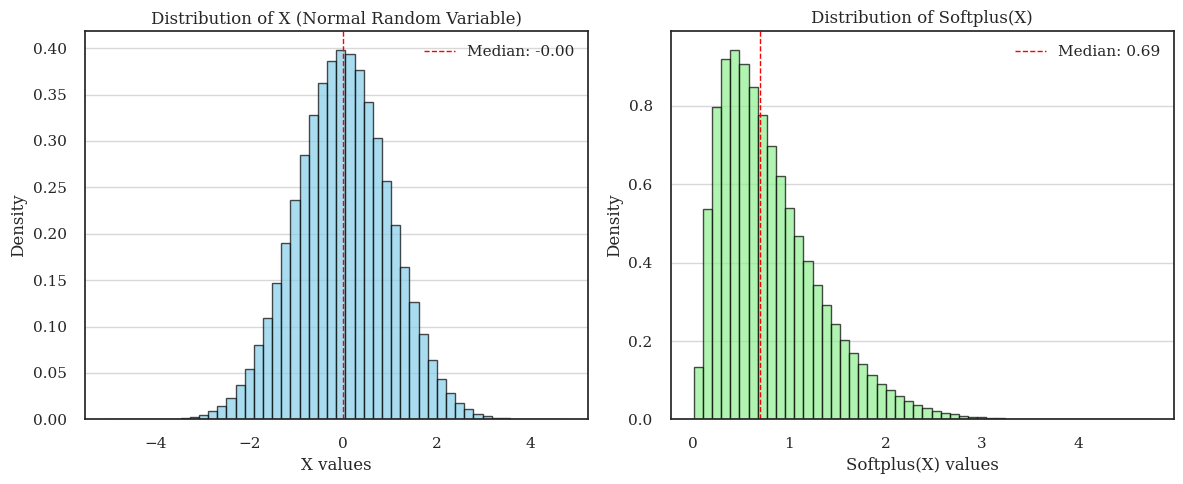

Mean of X: -0.0009
Standard Deviation of X: 1.0001
Mean of Softplus(X): 0.8056
Standard Deviation of Softplus(X): 0.5210
Minimum value of Softplus(X): 0.0065


<Figure size 800x550 with 0 Axes>

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the Softplus function
def softplus(x):
    """
    Computes the Softplus activation function: ln(1 + e^x)
    """
    return np.log(1 + np.exp(x))

# 2. Generate samples from a normal distribution (X)
# We'll use a large number of samples to get a smooth distribution
num_samples = 1000000
mean_x = 0  # Mean of the normal distribution
std_dev_x = 1 # Standard deviation of the normal distribution
X = np.random.normal(loc=mean_x, scale=std_dev_x, size=num_samples)

# 3. Apply the Softplus function to the normal random variable
Y_softplus = softplus(X)

# 4. Plotting the distributions
plt.figure(figsize=(12, 5))

# Plotting the original Normal distribution of X
plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
plt.hist(X, bins=50, density=True, alpha=0.7, color='skyblue', edgecolor='black')
plt.title('Distribution of X (Normal Random Variable)')
plt.xlabel('X values')
plt.ylabel('Density')
plt.grid(axis='y', alpha=0.75)
plt.axvline(np.median(X), color='red', linestyle='dashed', linewidth=1, label=f'Median: {np.median(X):.2f}')
plt.legend()
plt.tight_layout()

# Plotting the distribution of Softplus(X)
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
plt.hist(Y_softplus, bins=50, density=True, alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribution of Softplus(X)')
plt.xlabel('Softplus(X) values')
plt.ylabel('Density')
plt.grid(axis='y', alpha=0.75)
plt.axvline(np.median(Y_softplus), color='red', linestyle='dashed', linewidth=1, label=f'Median: {np.median(Y_softplus):.2f}')
plt.legend()
plt.tight_layout()

plt.show()

print(f"Mean of X: {X.mean():.4f}")
print(f"Standard Deviation of X: {X.std():.4f}")
print(f"Mean of Softplus(X): {Y_softplus.mean():.4f}")
print(f"Standard Deviation of Softplus(X): {Y_softplus.std():.4f}")
print(f"Minimum value of Softplus(X): {Y_softplus.min():.4f}")
plt.savefig("softplus-gaussian-demo.pdf")

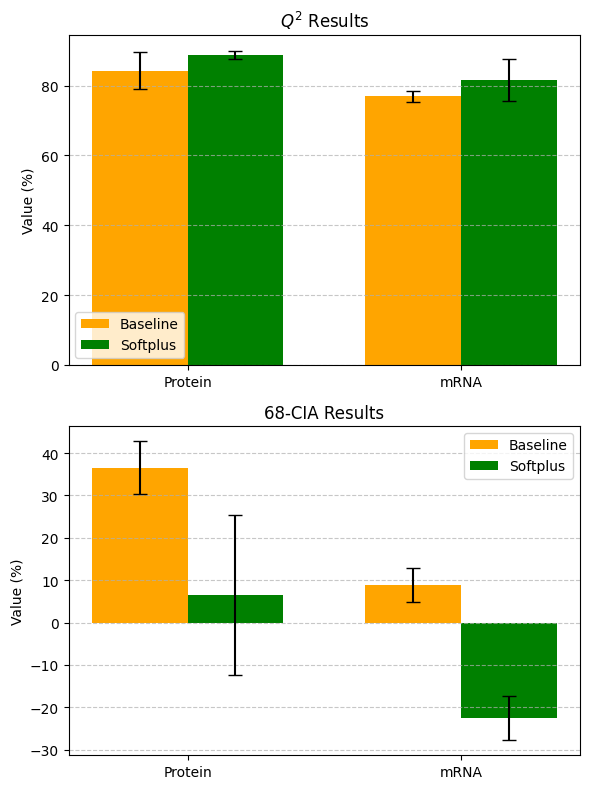

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Data from the user's provided table
data = {
    'Model': ['Baseline', 'Softplus'],
    'protein Q^2': [84.3, 88.8],
    'protein Q^2 error': [5.3, 1.1],
    'mRNA Q^2': [76.9, 81.6],
    'mRNA Q^2 error': [1.5, 6.1],
    'protein 68-CIA': [36.6, 6.6],
    'protein 68-CIA error': [6.3, 18.9],
    'mRNA 68-CIA': [8.8, -22.6],
    'mRNA 68-CIA error': [4.0, 5.2]
}

# Create a DataFrame
df = pd.DataFrame(data)

# Create two subplots
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(6, 8))

# --- Plot for Q^2 ---
# Data for Q^2 subplot
q2_baseline = df.loc[df['Model'] == 'Baseline', ['protein Q^2', 'mRNA Q^2']].values.flatten()
q2_softplus = df.loc[df['Model'] == 'Softplus', ['protein Q^2', 'mRNA Q^2']].values.flatten()
q2_baseline_err = df.loc[df['Model'] == 'Baseline', ['protein Q^2 error', 'mRNA Q^2 error']].values.flatten()
q2_softplus_err = df.loc[df['Model'] == 'Softplus', ['protein Q^2 error', 'mRNA Q^2 error']].values.flatten()

# Set up positions for the bars
x = np.arange(len(q2_baseline))
width = 0.35

# Plot bars for Baseline and Softplus models
axes[0].bar(x - width/2, q2_baseline, width, yerr=q2_baseline_err, label='Baseline', capsize=5, color='orange')
axes[0].bar(x + width/2, q2_softplus, width, yerr=q2_softplus_err, label='Softplus', capsize=5, color='green')

# Set labels, title, and legend
axes[0].set_ylabel('Value (%)')
axes[0].set_title('$Q^2$ Results')
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Protein', 'mRNA'])
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# --- Plot for 68-CIA ---
# Data for 68-CIA subplot
cia_baseline = df.loc[df['Model'] == 'Baseline', ['protein 68-CIA', 'mRNA 68-CIA']].values.flatten()
cia_softplus = df.loc[df['Model'] == 'Softplus', ['protein 68-CIA', 'mRNA 68-CIA']].values.flatten()
cia_baseline_err = df.loc[df['Model'] == 'Baseline', ['protein 68-CIA error', 'mRNA 68-CIA error']].values.flatten()
cia_softplus_err = df.loc[df['Model'] == 'Softplus', ['protein 68-CIA error', 'mRNA 68-CIA error']].values.flatten()

# Plot bars for Baseline and Softplus models
axes[1].bar(x - width/2, cia_baseline, width, yerr=cia_baseline_err, label='Baseline', capsize=5, color='orange')
axes[1].bar(x + width/2, cia_softplus, width, yerr=cia_softplus_err, label='Softplus', capsize=5, color='green')

# Set labels, title, and legend
axes[1].set_ylabel('Value (%)')
axes[1].set_title('68-CIA Results')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['Protein', 'mRNA'])
axes[1].legend()
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Adjust layout and save the figure
plt.tight_layout()
plt.savefig('model_comparison_bar_charts.png')